In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

data={
        "Study_Hours": [1,2,3,4,5,6,
                       1,2,3,4,5,6],
        "Result":[
            "Fail","Fail","Fail","Fail","Pass","Pass",
            "Fail","Fail","Fail","Pass","Pass","Pass"
        ]
}

df = pd.DataFrame(data)

print("STUDENT DATASET")
print(df)

X = df[["Study_Hours"]]
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))

model = LogisticRegression()

model.fit(X_train, y_train)

print("\nModel Trained Successfully!")

STUDENT DATASET
    Study_Hours Result
0             1   Fail
1             2   Fail
2             3   Fail
3             4   Fail
4             5   Pass
5             6   Pass
6             1   Fail
7             2   Fail
8             3   Fail
9             4   Pass
10            5   Pass
11            6   Pass

Training Records: 9
Testing Records: 3

Model Trained Successfully!



LEARNED MODEL PARAMETERS
Intercept: -4.672751946143805
Coefficient: [1.32475792]

ACTUAL RESULTS:
['Pass' 'Fail' 'Fail']

PREDICTED RESULTS:
['Pass' 'Fail' 'Pass']

PREDICTED PROBABILITIES:
[[0.03641094 0.96358906]
 [0.66785028 0.33214972]
 [0.34835457 0.65164543]]

ACTUAL VS PREDICTED RESULTS
   Study_Hours Actual_Result Predicted_Result
0            6          Pass             Pass
1            3          Fail             Fail
2            4          Fail             Pass


C:\Users\user\anaconda3\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


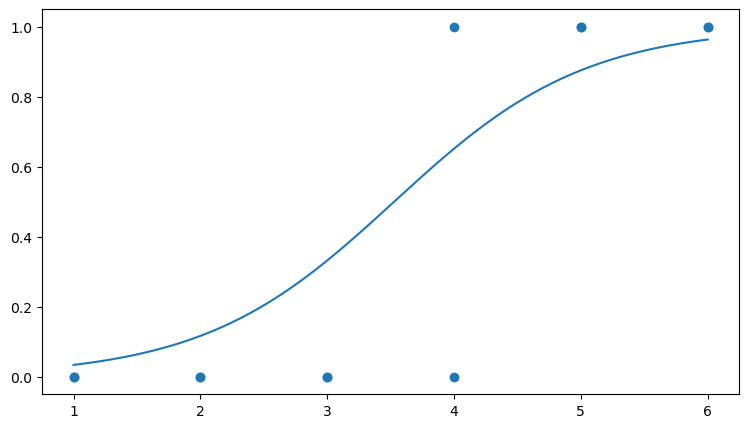

In [9]:
print("\nLEARNED MODEL PARAMETERS")

print("Intercept:", model.intercept_[0])
print("Coefficient:", model.coef_[0])

y_pred = model.predict(X_test)

print("\nACTUAL RESULTS:")
print(y_test.values)

print("\nPREDICTED RESULTS:")
print(y_pred)

y_prob = model.predict_proba(X_test)

print("\nPREDICTED PROBABILITIES:")
print(y_prob)

comparison = pd.DataFrame({
    'Study_Hours': X_test['Study_Hours'].values,
    'Actual_Result': y_test.values,
    'Predicted_Result': y_pred
})

print("\nACTUAL VS PREDICTED RESULTS")
print(comparison)

study_hours = np.linspace(
    df['Study_Hours'].min(),
    df['Study_Hours'].max(),
    200
).reshape(-1, 1)

pass_index = list(model.classes_).index("Pass")

probabilities = model.predict_proba(study_hours)[:, pass_index]

plt.figure(figsize=(9, 5))

plt.scatter(
    df['Study_Hours'],
    df['Result'].map({'Fail': 0, 'Pass': 1}),
    label="Actual Results"
)

plt.plot(
    study_hours,
    probabilities,
    label="Logistic Regression Curve"
)

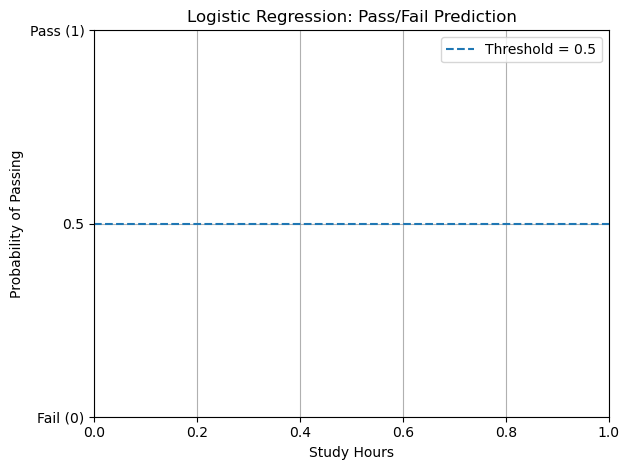


MODEL EVALUATION METRICS
Accuracy: 66.66666666666666 %

CONFUSION MATRIX
[[1 1]
 [0 1]]


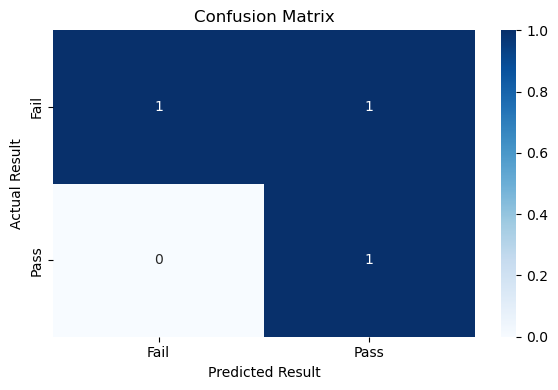

In [10]:
plt.axhline(
    y=0.5,
    linestyle='--',
    label="Threshold = 0.5"
)

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression: Pass/Fail Prediction")

plt.yticks(
    [0, 0.5, 1],
    ["Fail (0)", "0.5", "Pass (1)"]
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL EVALUATION METRICS")
print("Accuracy:", accuracy * 100, "%")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("\nCONFUSION MATRIX")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [11]:
precision = precision_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

print("Precision:", precision)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

print("Recall:", recall)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

print("F1-Score:", f1)

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        zero_division=0
    )
)

new_student = pd.DataFrame({
    "Study_Hours": [5]
})

prediction = model.predict(new_student)
probability = model.predict_proba(new_student)

print("\nNEW STUDENT DETAILS:")
print(new_student)

print("\nProbability of Fail:", probability[0][0])
print("Probability of Pass:", probability[0][1])

print("\nPREDICTED STUDENT RESULT:", prediction[0])

Precision: 0.5
Recall: 1.0
F1-Score: 0.6666666666666666

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fail       1.00      0.50      0.67         2
        Pass       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3


NEW STUDENT DETAILS:
   Study_Hours
0            5

Probability of Fail: 0.124440255152514
Probability of Pass: 0.875559744847486

PREDICTED STUDENT RESULT: Pass
